<a href="https://colab.research.google.com/github/mahveen1506/Machine-Learning/blob/main/heart_disease_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
import os

def find_file(name, path):
    for root, dirs, files in os.walk(path):
        if name in files:
            return os.path.join(root, name)
    return None

file_path = find_file('heart.csv', '/content/drive/MyDrive')
if file_path:
    print(f"Found file at: {file_path}")
    heart = pd.read_csv(file_path)
    print(heart.head())
    print("Shape of dataset:", heart.shape)
else:
    print("Could not find heart.csv in your Google Drive (MyDrive). Please check the file name or upload it directly.")

Found file at: /content/drive/MyDrive/heart.csv
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   57    1   0       102   233    0        1      172      0      0.5      2   
1   45    1   0       117   284    0        1      170      0      0.2      2   
2   61    0   2       122   345    0        0      168      0      0.4      1   
3   62    1   1       124   346    0        1      168      0      1.7      1   
4   36    0   3       132   183    0        0      164      0      0.8      1   

   ca  thal  target  
0   0     2       0  
1   0     2       0  
2   1     2       0  
3   0     1       1  
4   0     2       0  
Shape of dataset: (303, 14)


In [12]:
heart.info()
print(heart.isna().sum().sum(), heart.duplicated().sum())
print(heart['target'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB
0 0
target
1    204
0     99
Name: count, dtype: int64


In [13]:
heart = heart.dropna()
print("Shape after dropping missing values:", heart.shape)

Shape after dropping missing values: (303, 14)


In [14]:
X = heart.drop('target', axis=1)   # 13 clinical features
y = heart['target']                # Target: 0 / 1
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (303, 13)
Shape of y: (303,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)

Shape of X_train: (242, 13)
Shape of X_test: (61, 13)


In [16]:
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[11  7]
 [ 7 36]]
              precision    recall  f1-score   support

           0       0.61      0.61      0.61        18
           1       0.84      0.84      0.84        43

    accuracy                           0.77        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.77      0.77      0.77        61



In [17]:
knn = KNeighborsClassifier()          # default k = 5
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

[[ 6 12]
 [ 7 36]]
              precision    recall  f1-score   support

           0       0.46      0.33      0.39        18
           1       0.75      0.84      0.79        43

    accuracy                           0.69        61
   macro avg       0.61      0.59      0.59        61
weighted avg       0.66      0.69      0.67        61



In [18]:
for k in ['linear', 'rbf', 'poly']:
    svm = SVC(kernel=k, random_state=42)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    print(k, accuracy_score(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))

linear 0.8032786885245902
[[12  6]
 [ 6 37]]
rbf 0.7049180327868853
[[ 5 13]
 [ 5 38]]
poly 0.7868852459016393
[[ 9  9]
 [ 4 39]]


In [19]:
clf_train = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=42)
dt_train = clf_train.fit(X_train, y_train)
y_pred = dt_train.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 9  9]
 [ 4 39]]
              precision    recall  f1-score   support

           0       0.69      0.50      0.58        18
           1       0.81      0.91      0.86        43

    accuracy                           0.79        61
   macro avg       0.75      0.70      0.72        61
weighted avg       0.78      0.79      0.78        61



In [20]:
print(export_text(dt_train, feature_names=list(X.columns)))

|--- ca <= -0.15
|   |--- sex <= -0.38
|   |   |--- class: 0
|   |--- sex >  -0.38
|   |   |--- class: 1
|--- ca >  -0.15
|   |--- thal <= 0.33
|   |   |--- class: 1
|   |--- thal >  0.33
|   |   |--- class: 1



In [21]:
print(dict(zip(X.columns, dt_train.feature_importances_.round(3))))

{'age': np.float64(0.0), 'sex': np.float64(0.377), 'cp': np.float64(0.0), 'trestbps': np.float64(0.0), 'chol': np.float64(0.0), 'fbs': np.float64(0.0), 'restecg': np.float64(0.0), 'thalach': np.float64(0.0), 'exang': np.float64(0.0), 'oldpeak': np.float64(0.0), 'slope': np.float64(0.0), 'ca': np.float64(0.439), 'thal': np.float64(0.184)}


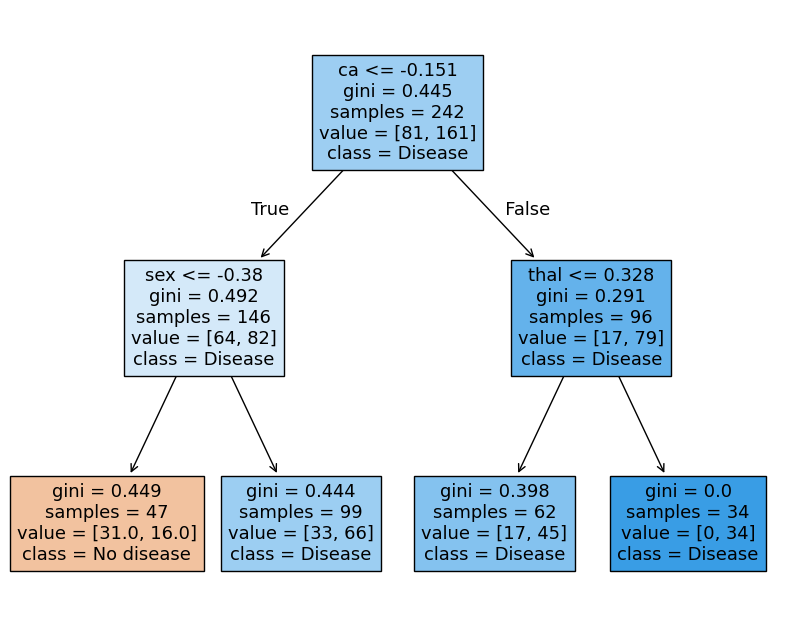

In [22]:
plt.figure(figsize=(10, 8))
tree.plot_tree(dt_train, feature_names=X.columns,
               class_names=['No disease', 'Disease'], filled=True)
plt.savefig('heart_tree.png')
plt.show()

In [23]:
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=1234)
clf.fit(X, y)
print(export_text(clf, feature_names=list(X.columns)))

|--- ca <= 0.50
|   |--- sex <= 0.50
|   |   |--- chol <= 308.00
|   |   |   |--- cp <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- cp >  1.50
|   |   |   |   |--- class: 0
|   |   |--- chol >  308.00
|   |   |   |--- chol <= 334.00
|   |   |   |   |--- class: 1
|   |   |   |--- chol >  334.00
|   |   |   |   |--- class: 0
|   |--- sex >  0.50
|   |   |--- oldpeak <= 0.75
|   |   |   |--- age <= 66.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  66.50
|   |   |   |   |--- class: 1
|   |   |--- oldpeak >  0.75
|   |   |   |--- thalach <= 161.50
|   |   |   |   |--- class: 1
|   |   |   |--- thalach >  161.50
|   |   |   |   |--- class: 1
|--- ca >  0.50
|   |--- thal <= 2.50
|   |   |--- thalach <= 154.50
|   |   |   |--- class: 1
|   |   |--- thalach >  154.50
|   |   |   |--- cp <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- cp >  1.50
|   |   |   |   |--- class: 0
|   |--- thal >  2.50
|   |   |--- class: 1

